In [4]:
import os
print("Current Working Directory:", os.getcwd())
print("Files in this directory:", os.listdir('.'))

Current Working Directory: c:\Users\darth\OneDrive\Documents\GitHub\boreal-reco-knikop\notebooks
Files in this directory: ['01_mining.ipynb']


In [6]:
print(os.listdir('../data'))

['products.csv', 'transactionsdata.zip']


## Phase 1

### Load and Verify data

In [ ]:
# 1.1
import pandas as pd, numpy as np, time
tx = pd.read_csv('../data/transactionsdata.zip', parse_dates=['Date'])
products = pd.read_csv('../data/products.csv')

print(tx['TransactionID'].nunique(), 'baskets')     # expect 1,000,000
print(tx['Item'].nunique(), 'products')              # expect 98
print(len(tx) / tx['TransactionID'].nunique())       # expect 8.38 items per basket
print(tx.duplicated(['TransactionID','Item']).sum()) # expect 0 (no item twice in a basket)

1000000 baskets
98 products
8.379837
0


In [ ]:
# 1.2
t = time.perf_counter()
row, basket_ids = pd.factorize(tx['TransactionID'])
col, items      = pd.factorize(tx['Item'])
B = np.zeros((len(basket_ids), len(items)), dtype=bool)
B[row, col] = True
basket = pd.DataFrame(B, index=basket_ids, columns=items)
print(f'{time.perf_counter()-t:.2f}s, {basket.memory_usage().sum()/1e6:.0f} MB')

1.11s, 106 MB


In [9]:
t = time.perf_counter()
naive = pd.crosstab(tx['TransactionID'], tx['Item']).astype(bool)   # ~65 s, int64 intermediate ~784 MB
print(time.perf_counter()-t)

63.30183789995499


In [14]:
# 1.3 - Product Freuencies
freq = basket.mean().sort_values(ascending=False)   # share of baskets containing each item
display(freq.head(10))
display(freq.tail(5))

Sac réutilisable     0.900026
Biscuits             0.161439
Noix mélangées       0.155189
Beurre d'arachide    0.153726
Bière                0.150468
Savon à vaisselle    0.149820
Fromage cheddar      0.143457
Charbon de bois      0.140561
Papier hygiénique    0.139758
Céréales             0.139198
dtype: float64

Safran                         0.000818
Huile de truffe                0.000817
Caviar                         0.000810
Vinaigre balsamique vieilli    0.000779
Foie gras                      0.000756
dtype: float64

# 1.4

lift(Baguette, Pain baguette rustique) = 1.027


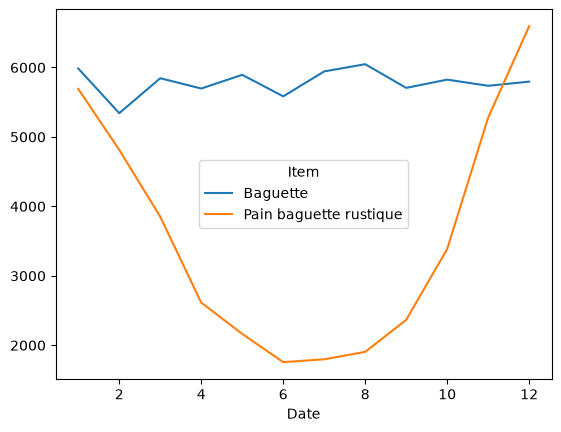

In [ ]:
# 1.5
monthly = tx.groupby([tx.Date.dt.month, 'Item']).size().unstack()
monthly[['Baguette', 'Pain baguette rustique']].plot()

a, b = basket['Baguette'], basket['Pain baguette rustique']
lift_ab = (a & b).mean() / (a.mean() * b.mean())

print(f'lift(Baguette, Pain baguette rustique) = {lift_ab:.3f}') # expected ~1.03

## Phase 2

In [12]:
from mlxtend.frequent_patterns import apriori, association_rules
try:
    apriori(basket, min_support=0.02, use_colnames=True)   # low_memory defaults to False
except MemoryError as e:
    print('MemoryError:', e)

MemoryError: Unable to allocate 7.97 GiB for an array with shape (4278, 2, 1000000) and data type bool


In [13]:
import time, tracemalloc
results = []
for ms in [0.05, 0.02, 0.01, 0.005]:
    tracemalloc.start(); t = time.perf_counter()
    itemsets = apriori(basket, min_support=ms, use_colnames=True, low_memory=True)
    rules = association_rules(itemsets, metric='confidence', min_threshold=0.1)
    elapsed = time.perf_counter() - t
    _, peak = tracemalloc.get_traced_memory(); tracemalloc.stop()
    results.append(dict(min_support=ms, itemsets=len(itemsets), rules=len(rules),
                        seconds=round(elapsed, 1), peak_GB=round(peak/1e9, 2),
                        longest=itemsets['itemsets'].map(len).max()))
pd.DataFrame(results)

,min_support,itemsets,rules,seconds,peak_GB,longest
0,0.050,191,306,3.7,0.16,4
1,0.020,658,3468,7.9,0.18,5
2,0.010,2267,13731,19.0,0.18,7
3,0.005,7106,41952,39.8,0.18,7


## Phase 3

## Phase 4

## Phase 5